In [33]:
import glob
import kagglehub
import numpy as np
import pandas as pd
import warnings

warnings.filterwarnings("ignore")

# Download dataset
path = kagglehub.dataset_download("shahidabbas76/nf-ton-iot-v2-full-dataset")
print("Path to dataset files:", path)

csv_files = glob.glob(f"{path}/**/*.csv", recursive=True)
print("Found CSVs:", csv_files)

# Load restricted rows for stability
print("Loading dataset...")
df = pd.read_csv(csv_files[0], nrows=1000000)
print(f"Dataset shape loaded: {df.shape}")

Path to dataset files: /kaggle/input/datasets/shahidabbas76/nf-ton-iot-v2-full-dataset
Found CSVs: ['/kaggle/input/datasets/shahidabbas76/nf-ton-iot-v2-full-dataset/NF-ToN-IoT-v2.csv']
Loading dataset...
Dataset shape loaded: (1000000, 45)


In [34]:
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import numpy as np
import pandas as pd

# 1. Stratified subsample
df_sub, _ = train_test_split(
    df, test_size=0.7, stratify=df["Label"], random_state=42
)

# 2. Clean columns (Drop IPs, ports, timestamps, multi-class label)
drop_cols = [
    "IPV4_SRC_ADDR",
    "IPV4_DST_ADDR",
    "L4_SRC_PORT",
    "L4_DST_PORT",
    "TIMESTAMP",
    "Attack",
]
df_clean = df_sub.drop(columns=[col for col in drop_cols if col in df_sub.columns])

X = df_clean.drop(columns=["Label"])
y = df_clean["Label"]

# 3. Handle infinities and NaNs globally on X FIRST
X.replace([np.inf, -np.inf], np.nan, inplace=True)
imputer = SimpleImputer(strategy="constant", fill_value=0)
X_imputed = pd.DataFrame(imputer.fit_transform(X), columns=X.columns)

# 4. Drop constant columns (zero variance)
const_cols = [col for col in X_imputed.columns if X_imputed[col].nunique() <= 1]
X_imputed = X_imputed.drop(columns=const_cols)

# 5. Split 60 / 20 / 20
X_train, X_temp, y_train, y_temp = train_test_split(
    X_imputed, y, test_size=0.4, stratify=y, random_state=42
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=42
)

# 6. Standardize & Double-Check for any rogue NaNs created during scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

# Final safety net: replace any accidental NaN/inf with 0 in the scaled arrays
X_train_scaled = np.nan_to_num(X_train_scaled, nan=0.0, posinf=0.0, neginf=0.0)
X_val_scaled = np.nan_to_num(X_val_scaled, nan=0.0, posinf=0.0, neginf=0.0)
X_test_scaled = np.nan_to_num(X_test_scaled, nan=0.0, posinf=0.0, neginf=0.0)

# 7. Filter Benign Data for Unsupervised Training
benign_mask = y_train.values == 0
X_train_benign = X_train_scaled[benign_mask]

print(f"Data prep complete! Train benign shape: {X_train_benign.shape}")
print("Any NaNs left in X_train_scaled:", np.isnan(X_train_scaled).any())

Data prep complete! Train benign shape: (108462, 39)
Any NaNs left in X_train_scaled: False


In [35]:
from sklearn.ensemble import IsolationForest
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import f1_score

# 1. Compute Mutual Information ranking on training set using SURVIVING columns
mi_scores = mutual_info_classif(X_train_scaled, y_train)

# Use X_train.columns (which already has constant columns dropped in Cell 2)
feature_rankings = sorted(
    zip(X_train.columns, mi_scores), key=lambda x: x[1], reverse=True
)
ranked_features = [feat for feat, score in feature_rankings]
feature_map = {col: idx for idx, col in enumerate(X_train.columns)}

print("Top 5 Ranked Features:", ranked_features[:5])


# 2. Helper function to evaluate Isolation Forest
def evaluate_iso_forest(X_tr_b, X_v, y_v, feature_indices):
    iso = IsolationForest(
        n_estimators=100, contamination=0.1, random_state=42, n_jobs=-1
    )
    iso.fit(X_tr_b[:, feature_indices])
    preds = iso.predict(X_v[:, feature_indices])
    preds_binary = np.where(preds == -1, 1, 0)
    return f1_score(y_v, preds_binary)


# 3. Global Baseline (All features)
all_indices = list(range(X_train_scaled.shape[1]))
baseline_val_f1 = evaluate_iso_forest(
    X_train_benign, X_val_scaled, y_val, all_indices
)
print(f"\nGlobal Baseline Validation F1 (All Features): {baseline_val_f1:.4f}")

# 4. Tune k using top-ranked features
# Ensure max k does not exceed the total number of remaining columns
max_features = X_train_scaled.shape[1]
k_values = [5, 10, 15, 20, 25, 30, max_features]
k_values = [k for k in k_values if k <= max_features]  # safety filter

val_f1_scores = []

print("\nTuning k on Validation Set:")
for k in k_values:
    top_k_cols = ranked_features[:k]
    indices = [feature_map[col] for col in top_k_cols]
    f1 = evaluate_iso_forest(X_train_benign, X_val_scaled, y_val, indices)
    val_f1_scores.append(f1)
    print(f"k = {k} | Validation F1: {f1:.4f}")

optimal_k = k_values[np.argmax(val_f1_scores)]
print(f"\nOptimal k chosen: {optimal_k}")

Top 5 Ranked Features: ['IN_BYTES', 'SRC_TO_DST_AVG_THROUGHPUT', 'TCP_WIN_MAX_IN', 'LONGEST_FLOW_PKT', 'MAX_IP_PKT_LEN']

Global Baseline Validation F1 (All Features): 0.9461

Tuning k on Validation Set:
k = 5 | Validation F1: 0.9754
k = 10 | Validation F1: 0.9753
k = 15 | Validation F1: 0.9510
k = 20 | Validation F1: 0.9510
k = 25 | Validation F1: 0.9461
k = 30 | Validation F1: 0.9461
k = 39 | Validation F1: 0.9461

Optimal k chosen: 5


=== Final Test Results (Optimized Model) ===
F1-Score: 0.9758
MCC:      0.9599
PR-AUC:   0.6398

Saved results table to cns_project_results.csv


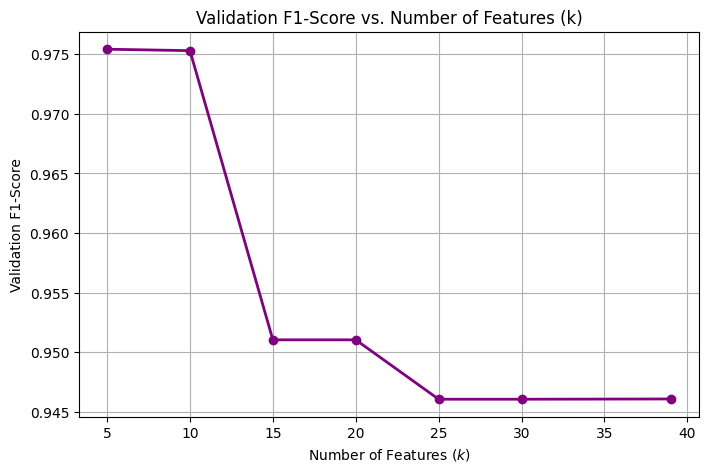

Saved plot to f1_vs_k_plot.png


In [36]:
from sklearn.metrics import auc, f1_score, matthews_corrcoef, precision_recall_curve
import matplotlib.pyplot as plt

# 1. Train final model with optimal k features
optimal_indices = [feature_map[col] for col in ranked_features[:optimal_k]]

final_iso = IsolationForest(
    n_estimators=100, contamination=0.1, random_state=42, n_jobs=-1
)
final_iso.fit(X_train_benign[:, optimal_indices])

# 2. Test set inference
test_scores = final_iso.decision_function(X_test_scaled[:, optimal_indices])
test_preds_raw = final_iso.predict(X_test_scaled[:, optimal_indices])
test_preds = np.where(test_preds_raw == -1, 1, 0)

# 3. Compute metrics
test_f1 = f1_score(y_test, test_preds)
test_mcc = matthews_corrcoef(y_test, test_preds)
precision, recall, _ = precision_recall_curve(y_test, -test_scores)
test_pr_auc = auc(recall, precision)

print("=== Final Test Results (Optimized Model) ===")
print(f"F1-Score: {test_f1:.4f}")
print(f"MCC:      {test_mcc:.4f}")
print(f"PR-AUC:   {test_pr_auc:.4f}")

# 4. Save results table
results_df = pd.DataFrame(
    [
        {
            "Model": "Isolation Forest (Baseline - All Features)",
            "F1": baseline_val_f1,
            "MCC": "N/A",
            "PR-AUC": "N/A",
        },
        {
            "Model": f"Isolation Forest (Optimized, k={optimal_k})",
            "F1": test_f1,
            "MCC": test_mcc,
            "PR-AUC": test_pr_auc,
        },
    ]
)
results_df.to_csv("cns_project_results.csv", index=False)
print("\nSaved results table to cns_project_results.csv")

# 5. Generate and save plot
plt.figure(figsize=(8, 5))
plt.plot(
    k_values,
    val_f1_scores,
    marker="o",
    linestyle="-",
    color="purple",
    linewidth=2,
)
plt.title("Validation F1-Score vs. Number of Features (k)")
plt.xlabel("Number of Features ($k$)")
plt.ylabel("Validation F1-Score")
plt.grid(True)
plt.savefig("f1_vs_k_plot.png", dpi=300, bbox_inches="tight")
plt.show()
print("Saved plot to f1_vs_k_plot.png")
